# Ticket Dataset

In this notebook, I’m checking:
- how the ticket categories are distributed
- how long tickets are (characters + words)
- how ticket length differs by category

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# Set seaborn style for plots
sns.set(style="whitegrid")

In [2]:
# Load dataset
file_path = "all_tickets_processed_improved_v3.csv"
df_tickets = pd.read_csv(file_path, encoding="ascii")

df_tickets.head()


,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [3]:
# Display basic info about the dataset
df_tickets.info()
print("\nMissing values:\n", df_tickets.isna().sum())
print("\nColumns:", df_tickets.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     47837 non-null  object
 1   Topic_group  47837 non-null  object
dtypes: object(2)
memory usage: 747.6+ KB

Missing values:
 Document       0
Topic_group    0
dtype: int64

Columns: ['Document', 'Topic_group']


## Basic dataset stats

Here I’m checking:
- number of tickets
- number of categories
- which categories appear the most

In [4]:
num_tickets = len(df_tickets)
categories = df_tickets["Topic_group"].astype(str)

category_counts = categories.value_counts()
category_proportions = (category_counts / num_tickets) * 100

print("Total tickets:", num_tickets)
print("Unique categories:", categories.nunique())

print("\nCounts:\n", category_counts)
print("\nPercentages:\n", category_proportions.round(2))

Total tickets: 47837
Unique categories: 8

Counts:
 Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

Percentages:
 Topic_group
Hardware                 28.47
HR Support               22.82
Access                   14.89
Miscellaneous            14.76
Storage                   5.81
Purchase                  5.15
Internal Project          4.43
Administrative rights     3.68
Name: count, dtype: float64


## Class distribution using NumPy 

This is the same idea as `value_counts()`, but done with `np.unique()`.
Then I grab the biggest/smallest classes to see how imbalanced the dataset is.

In [5]:
# Class imbalance analysis
labels_np = categories.to_numpy()
unique_labels, label_counts = np.unique(labels_np, return_counts=True)

majority_idx = np.argmax(label_counts)
minority_idx = np.argmin(label_counts)
majority_class = unique_labels[majority_idx]
minority_class = unique_labels[minority_idx]
class_imbalance_ratio = label_counts[majority_idx] / float(label_counts[minority_idx])

print("Unique labels:", unique_labels)
print("Counts:", label_counts)

print("\nMajority class:", majority_class)
print("Minority class:", minority_class)
print("Imbalance ratio (max/min):", round(class_imbalance_ratio, 2))


Unique labels: ['Access' 'Administrative rights' 'HR Support' 'Hardware'
 'Internal Project' 'Miscellaneous' 'Purchase' 'Storage']
Counts: [ 7125  1760 10915 13617  2119  7060  2464  2777]

Majority class: Hardware
Minority class: Administrative rights
Imbalance ratio (max/min): 7.74


## Ticket length features 

I convert each ticket into:
- character length
- word count

These are quick features you can use for EDA and sometimes even modeling.

In [6]:

# Text size and complexity arrays
texts = df_tickets["Document"].fillna("")
char_lengths = texts.str.len().to_numpy()
word_lengths = texts.str.split().str.len().to_numpy()

print(char_lengths[:5])
print(word_lengths[:5])

# Add text length features to the DataFrame
df_tickets["Document"] = df_tickets["Document"].fillna("").astype(str)

df_tickets["char_length"] = df_tickets["Document"].str.len()
df_tickets["word_length"] = df_tickets["Document"].str.split().str.len()

df_tickets[["Document", "char_length", "word_length", "Topic_group"]].head()



[111 124  93 948 115]
[ 18  19  14 145  15]


,Document,char_length,word_length,Topic_group
0,connection with icon icon dear please setup ic...,111,18,Hardware
1,work experience user work experience user hi w...,124,19,Access
2,requesting for meeting requesting meeting hi p...,93,14,Hardware
3,reset passwords for external accounts re expir...,948,145,Access
4,mail verification warning hi has got attached ...,115,15,Miscellaneous


## Word-length stats by category 

For each category, I calculate:
- average word count
- median word count
- standard deviation
- min & max word count

In [7]:
# find statistics per category
word_lengths = df_tickets["word_length"].to_numpy()

cat_stats = []
for cat in category_counts.index:  
    mask = (df_tickets["Topic_group"] == cat).to_numpy()
    lengths_cat = word_lengths[mask]

    cat_stats.append({
        "category": cat,
        "mean_words": float(np.mean(lengths_cat)),
        "median_words": float(np.median(lengths_cat)),
        "std_words": float(np.std(lengths_cat)),
        "min_words": int(np.min(lengths_cat)),
        "max_words": int(np.max(lengths_cat)),
    })

cat_stats_df = pd.DataFrame(cat_stats).sort_values("mean_words", ascending=False)
cat_stats_df


,category,mean_words,median_words,std_words,min_words,max_words
0,Hardware,56.273041,32.0,75.517449,2,931
7,Administrative rights,50.361932,30.0,63.835560,3,981
3,Miscellaneous,42.953966,27.0,52.182649,2,953
1,HR Support,37.766651,24.0,42.284288,2,817
6,Internal Project,37.706937,24.0,44.542692,4,876
2,Access,35.600000,22.0,47.188369,2,934
5,Purchase,34.932630,30.0,25.861620,2,418
4,Storage,34.409795,21.0,42.896857,5,497


## Plot: tickets per category(Bar chart)

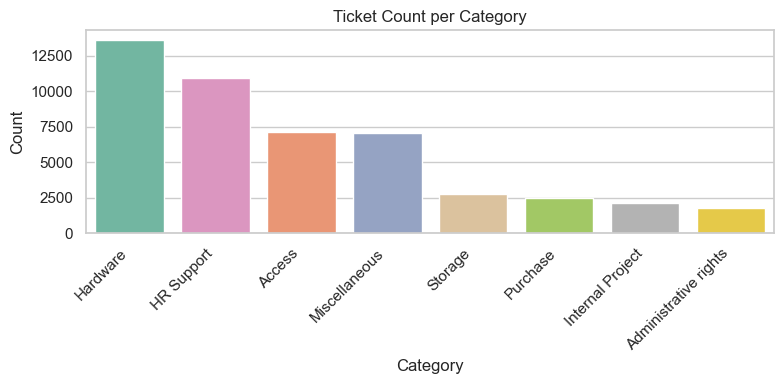

In [8]:
# Visualization of class distribution
plt.figure(figsize=(8, 4))
sns.countplot(
    data=df_tickets,
    x="Topic_group",
    hue="Topic_group",
    order=category_counts.index,
    palette="Set2",
    legend=False
)
plt.xticks(rotation=45, ha="right")
plt.title("Ticket Count per Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


## Plot: tickets per category (boxplot)

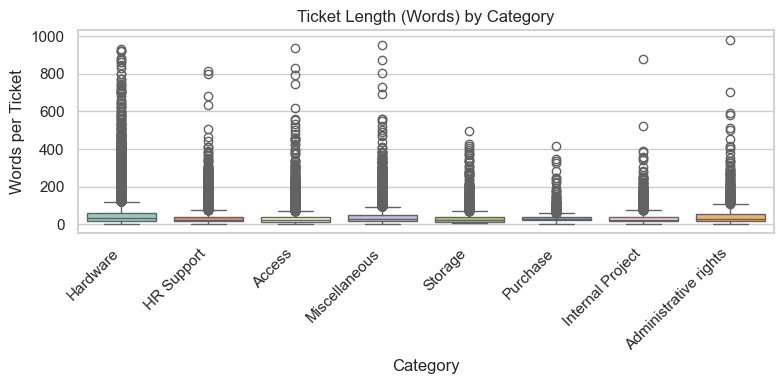

In [9]:

# Boxplot of ticket length (words) by category
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_tickets, x="Topic_group", hue="Topic_group", y="word_length", palette="Set3", order=category_counts.index)
plt.xticks(rotation=45, ha="right")
plt.title("Ticket Length (Words) by Category")
plt.xlabel("Category")
plt.ylabel("Words per Ticket")
plt.tight_layout()
plt.show()


## Plot: overall ticket length distribution (Histogram)

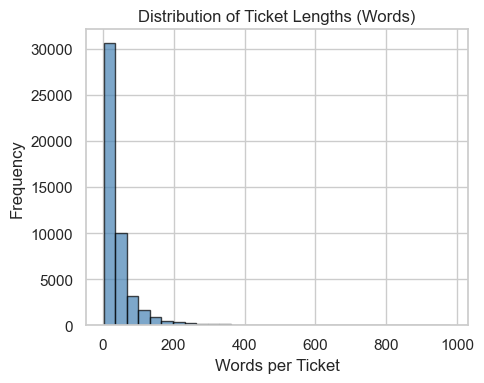

In [10]:

# Histogram of ticket lengths (words)
plt.figure(figsize=(5, 4))
plt.hist(word_lengths, bins=30, color="steelblue", edgecolor="black", alpha=0.7)
plt.title("Distribution of Ticket Lengths (Words)")
plt.xlabel("Words per Ticket")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## Plot: percentage of tickets per category

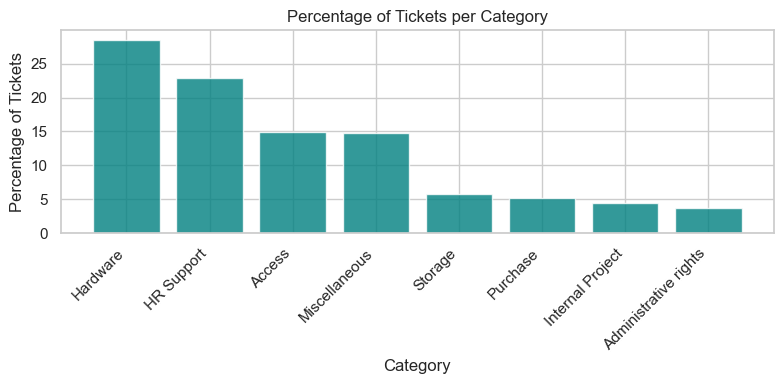

In [11]:
# Prepare data for normalized bar plot
word_lengths = df_tickets["word_length"].to_numpy()
category_counts = df_tickets["Topic_group"].value_counts()
category_proportions = category_counts / float(df_tickets.shape[0]) * 100

plt.figure(figsize=(8, 4))
plt.bar(category_proportions.index, category_proportions.values, color="teal", alpha=0.8)
plt.xticks(rotation=45, ha="right")
plt.title("Percentage of Tickets per Category")
plt.xlabel("Category")
plt.ylabel("Percentage of Tickets")
plt.tight_layout()
plt.show()


## Plot: ticket length vs category (stripplot)

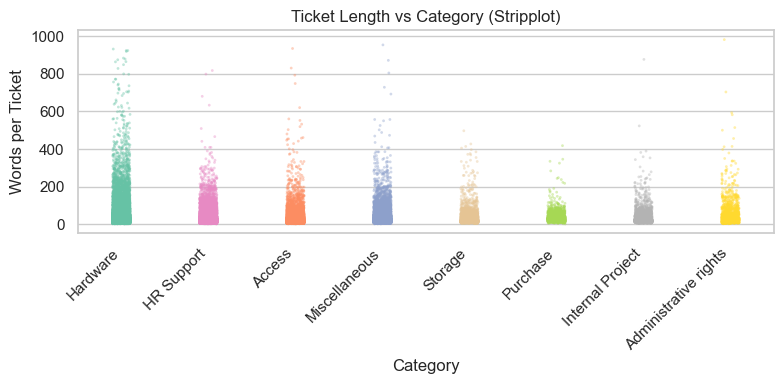

In [12]:
plt.figure(figsize=(8, 4))
sns.stripplot(data=df_tickets, x="Topic_group", hue="Topic_group", y="word_length", order=category_counts.index,
              jitter=True, alpha=0.4, size=2, palette="Set2")
plt.xticks(rotation=45, ha="right")
plt.title("Ticket Length vs Category (Stripplot)")
plt.xlabel("Category")
plt.ylabel("Words per Ticket")
plt.tight_layout()
plt.show()


## Plot: length distribution by category (violin plot)

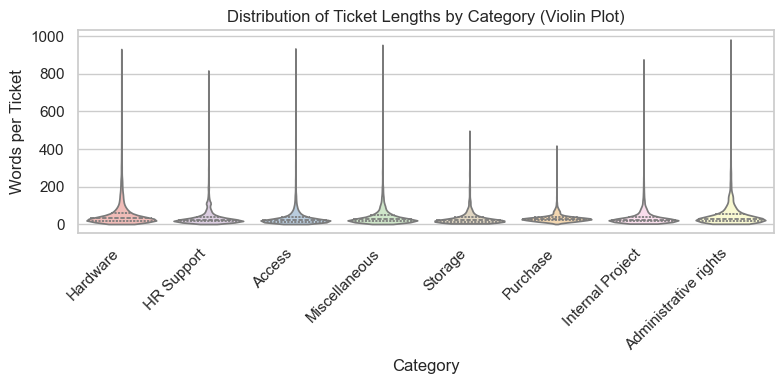

In [13]:
plt.figure(figsize=(8, 4))
sns.violinplot(data=df_tickets, x="Topic_group", hue="Topic_group", y="word_length", order=category_counts.index,
               palette="Pastel1", cut=0, inner="quartile")
plt.xticks(rotation=45, ha="right")
plt.title("Distribution of Ticket Lengths by Category (Violin Plot)")
plt.xlabel("Category")
plt.ylabel("Words per Ticket")
plt.tight_layout()
plt.show()

## Comparing two categories with NumPy stats

Here I compare two categories using:
- mean
- median
- IQR (middle 50% spread)

In [14]:
# Display statistics for two specific categories (Hardware vs Access)
cat_a = "Hardware"
cat_b = "Access"

# Create masks for the two categories
mask_a = df_tickets["Topic_group"] == cat_a
mask_b = df_tickets["Topic_group"] == cat_b

# Extract word lengths for each category
lengths_a = word_lengths[mask_a.to_numpy()]
lengths_b = word_lengths[mask_b.to_numpy()]

# Means and medians
mean_a = np.mean(lengths_a)
median_a = np.median(lengths_a)
mean_b = np.mean(lengths_b)
median_b = np.median(lengths_b)

# IQRs
q1_a, q3_a = np.percentile(lengths_a, [25, 75])
iqr_a = q3_a - q1_a
q1_b, q3_b = np.percentile(lengths_b, [25, 75])
iqr_b = q3_b - q1_b


print(f"{cat_a} -> mean: {mean_a:.2f}, median: {median_a:.2f}, IQR: {iqr_a:.2f}")
print(f"{cat_b} -> mean: {mean_b:.2f}, median: {median_b:.2f}, IQR: {iqr_b:.2f}")

Hardware -> mean: 56.27, median: 32.00, IQR: 41.00
Access -> mean: 35.60, median: 22.00, IQR: 23.00
